# Fragrance Data: Exploratory, Statistical & Predictive Analysis

Companion to the chord-diagram notebook (`Fragrance.ipynb`). This notebook uses the same `fra_cleaned.csv`
(Fragrantica-style data: perfume, brand, country, gender, rating, release year, top/middle/base notes, main accords).

## Setup & cleaning

In [1]:
import warnings, collections, itertools
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats, sparse

from sklearn.preprocessing import MultiLabelBinarizer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.decomposition import TruncatedSVD
from sklearn.cluster import KMeans
from sklearn.metrics import (silhouette_score, adjusted_rand_score, r2_score,
                             mean_squared_error, classification_report, confusion_matrix)
from sklearn.model_selection import train_test_split
from sklearn.linear_model import RidgeCV, LogisticRegression
from sklearn.ensemble import HistGradientBoostingRegressor

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110
SEED = 42
CSV = "fra_cleaned.csv"

# ---- tunable parameters ----
PRIOR_M = 100        # strength of the Bayesian rating prior (pseudo-votes)
MIN_RATINGS = 50     # minimum rating count for statistical tests / models
MIN_NOTE = 50        # minimum number of perfumes for a note to be analysed

In [2]:
raw = pd.read_csv(CSV, sep=";", encoding="latin-1")
df = raw.rename(columns={"Rating Value": "rating", "Rating Count": "n_ratings",
                         "Perfume": "perfume", "Brand": "brand", "Country": "country",
                         "Gender": "gender", "Year": "year"}).copy()

# Ratings use a decimal comma ("1,42")
df["rating"] = df["rating"].astype(str).str.replace(",", ".", regex=False).astype(float)
df["n_ratings"] = pd.to_numeric(df["n_ratings"], errors="coerce")
df["year"] = pd.to_numeric(df["year"], errors="coerce")
df["decade"] = (df["year"] // 10 * 10)

# "unknown" perfumer -> missing
for c in ["Perfumer1", "Perfumer2"]:
    df[c] = df[c].where(~df[c].isin(["unknown", ""]))

def split_notes(s):
    if pd.isna(s): return []
    return [n.strip() for n in str(s).split(",") if n.strip() and n.strip() not in ("unknown", "nan")]

for col in ["Top", "Middle", "Base"]:
    df[col + "_list"] = df[col].apply(split_notes)
df["all_notes"] = df.apply(lambda r: sorted(set(r["Top_list"] + r["Middle_list"] + r["Base_list"])), axis=1)

acc_cols = [f"mainaccord{i}" for i in range(1, 6)]
df["accords"] = df[acc_cols].apply(lambda r: [a.strip() for a in r if isinstance(a, str) and a.strip()], axis=1)

df["label"] = (df["perfume"].str.replace("-", " ").str.title() + " (" +
               df["brand"].str.replace("-", " ").str.title() + ")")

# Bayesian-adjusted rating: shrink low-count ratings toward the global mean
C_GLOBAL = np.average(df["rating"], weights=df["n_ratings"])
df["adj_rating"] = (df["n_ratings"] * df["rating"] + PRIOR_M * C_GLOBAL) / (df["n_ratings"] + PRIOR_M)

print("shape:", df.shape, "| duplicate URLs:", df["url"].duplicated().sum())
print("rating range:", df["rating"].min(), "-", df["rating"].max(), "| global weighted mean:", round(C_GLOBAL, 3))
print("missing year: %.1f%% | known perfumer: %.1f%%" % (df["year"].isna().mean()*100, df["Perfumer1"].notna().mean()*100))
print("avg notes per perfume: %.1f | avg accords: %.1f" % (df["all_notes"].str.len().mean(), df["accords"].str.len().mean()))
df[["label", "gender", "country", "year", "rating", "n_ratings", "adj_rating"]].head()


shape: (24063, 26) | duplicate URLs: 0
rating range: 1.42 - 4.93 | global weighted mean: 3.997
missing year: 8.5% | known perfumer: 48.8%
avg notes per perfume: 9.8 | avg accords: 4.9


,label,gender,country,year,rating,n_ratings,adj_rating
0,Accento Overdose Pride Edition (Xerjoff),unisex,Italy,2022.0,1.42,201,2.276160
1,Classique Pride 2024 (Jean Paul Gaultier),women,France,2024.0,1.86,70,3.117084
2,Classique Pride 2023 (Jean Paul Gaultier),unisex,France,2023.0,1.91,285,2.452089
3,Pride Edition Man (Bruno Banani),men,Germany,2019.0,1.92,59,3.226316
4,Le Male Pride Collector (Jean Paul Gaultier),men,France,2020.0,1.93,632,2.212383


## Exploratory analysis

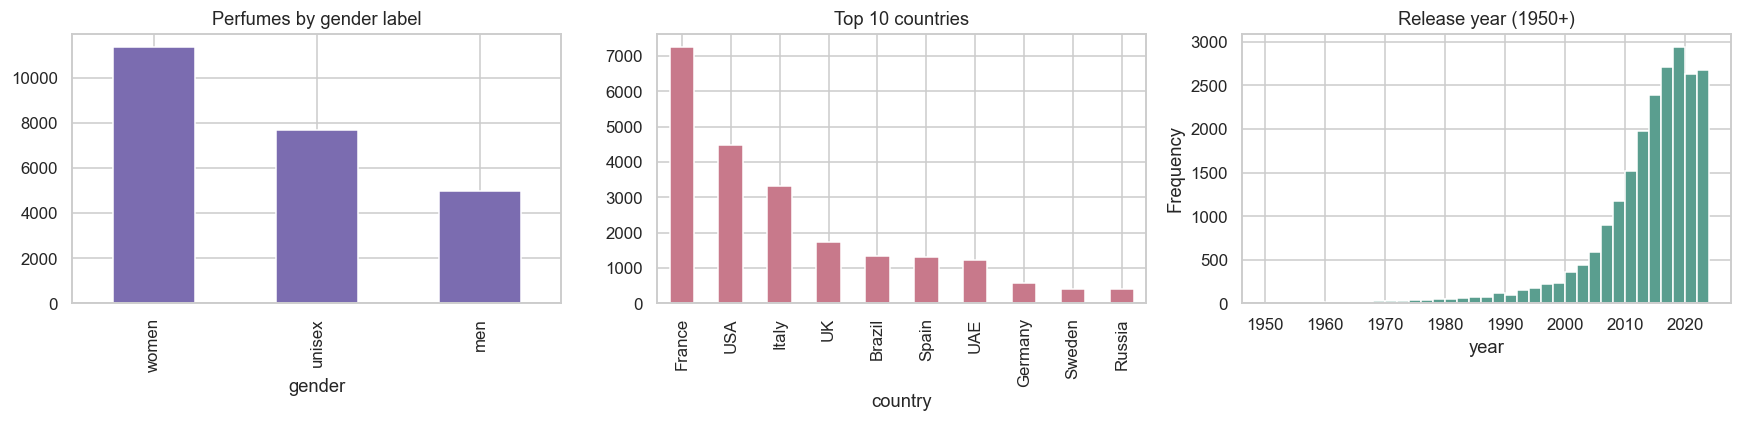

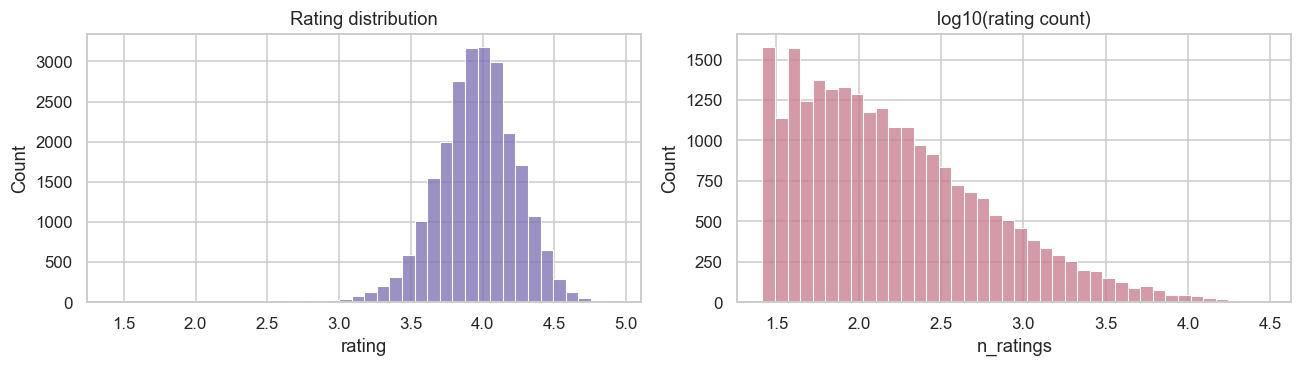

In [3]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
df["gender"].value_counts().plot.bar(ax=ax[0], color="#7b6cb0"); ax[0].set_title("Perfumes by gender label")
df["country"].value_counts().head(10).plot.bar(ax=ax[1], color="#c8798b"); ax[1].set_title("Top 10 countries")
df["year"].dropna().astype(int).plot.hist(bins=range(1950, 2026, 2), ax=ax[2], color="#5a9e8f")
ax[2].set_title("Release year (1950+)"); ax[2].set_xlabel("year")
plt.tight_layout(); plt.show()

fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
sns.histplot(df["rating"], bins=40, ax=ax[0], color="#7b6cb0"); ax[0].set_title("Rating distribution")
sns.histplot(np.log10(df["n_ratings"]), bins=40, ax=ax[1], color="#c8798b"); ax[1].set_title("log10(rating count)")
plt.tight_layout(); plt.show()

### Main accords over time
Share of perfumes (by decade) that list each accord among their five main accords.

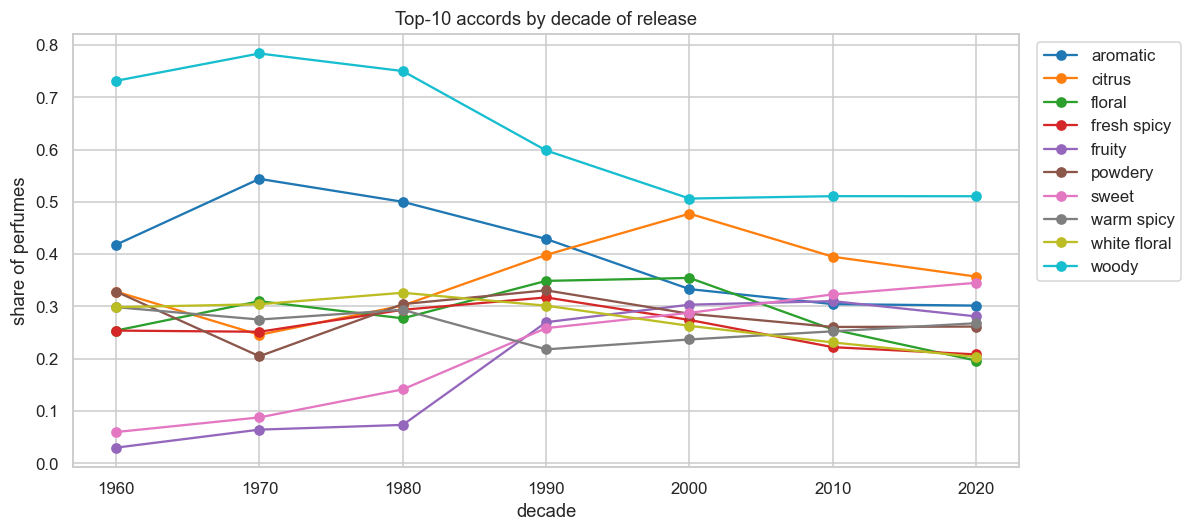

perfumes per decade: {1960.0: 67, 1970.0: 171, 1980.0: 368, 1990.0: 886, 2000.0: 3459, 2010.0: 11533, 2020.0: 5309}


In [4]:
# one row per (perfume, accord)
acc_long = df[["label", "gender", "country", "brand", "decade", "rating", "n_ratings", "accords"]].explode("accords").rename(columns={"accords": "accord"})
acc_long = acc_long.dropna(subset=["accord"])

top_accords = acc_long["accord"].value_counts().head(10).index.tolist()
dec = df[df["decade"] >= 1960]
dec_n = dec.groupby("decade").size()
trend = (acc_long[(acc_long["decade"] >= 1960) & acc_long["accord"].isin(top_accords)]
         .groupby(["decade", "accord"]).size().unstack(fill_value=0).div(dec_n, axis=0))

fig, ax = plt.subplots(figsize=(11, 5))
trend.plot(ax=ax, marker="o", colormap="tab10")
ax.set_ylabel("share of perfumes"); ax.set_title("Top-10 accords by decade of release")
ax.legend(bbox_to_anchor=(1.01, 1), loc="upper left"); plt.tight_layout(); plt.show()
print("perfumes per decade:", dec_n.to_dict())

### Gender and country profiles

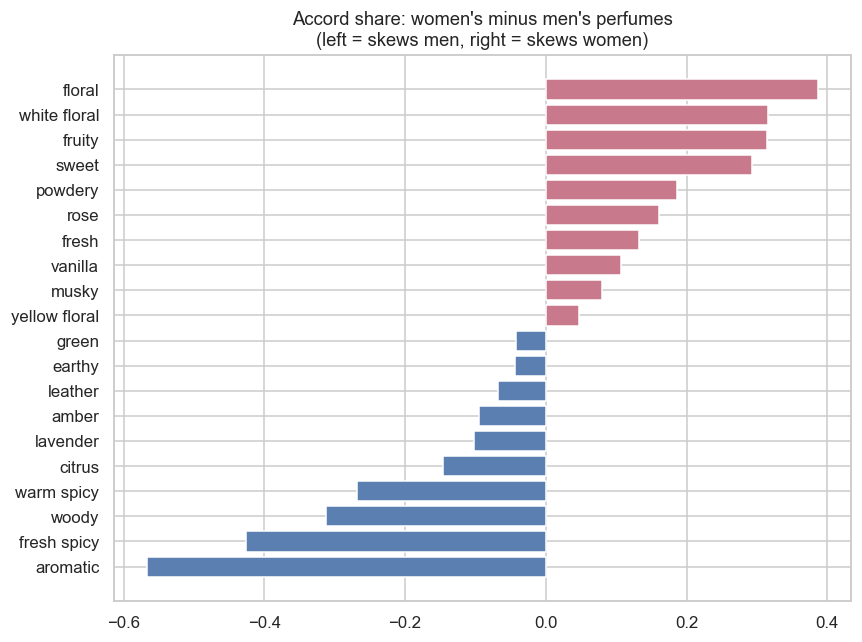

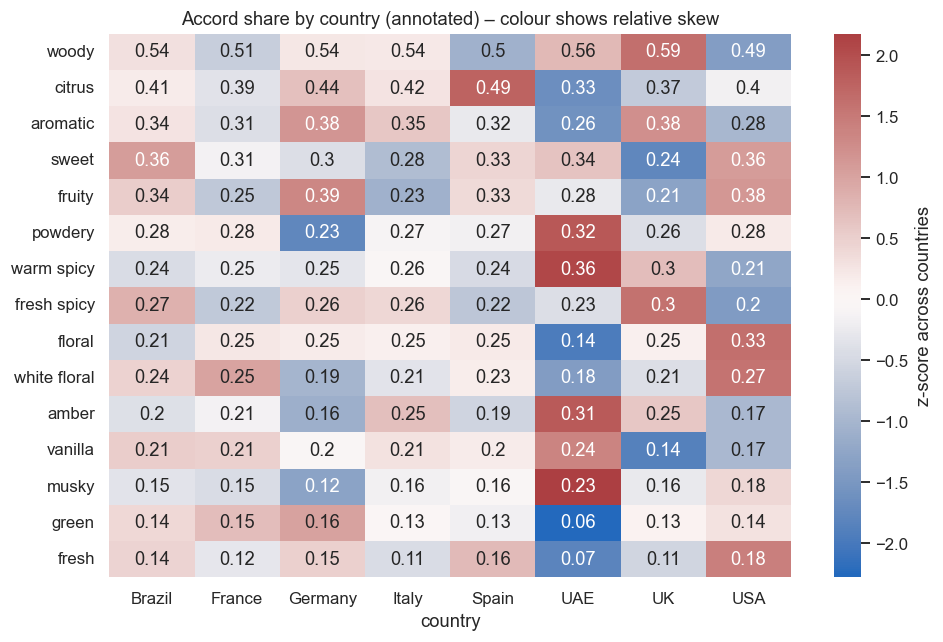

In [5]:
A = pd.DataFrame(MultiLabelBinarizer().fit_transform(df["accords"]), index=df.index,
                 columns=sorted({a for l in df["accords"] for a in l}))
A.columns = sorted({a for l in df["accords"] for a in l})
mlb_tmp = MultiLabelBinarizer(); mlb_tmp.fit(df["accords"]); A.columns = mlb_tmp.classes_

by_gender = A.groupby(df["gender"]).mean().T
by_gender["women_minus_men"] = by_gender["women"] - by_gender["men"]
d = by_gender.sort_values("women_minus_men")
sel = pd.concat([d.head(10), d.tail(10)])

fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(sel.index, sel["women_minus_men"], color=np.where(sel["women_minus_men"] > 0, "#c8798b", "#5a7fb0"))
ax.set_title("Accord share: women's minus men's perfumes\n(left = skews men, right = skews women)")
plt.tight_layout(); plt.show()

top_c = df["country"].value_counts().head(8).index
by_country = A[df["country"].isin(top_c)].groupby(df["country"]).mean().T
by_country = by_country.loc[by_country.mean(axis=1).sort_values(ascending=False).head(15).index]
# z-score across countries so differences (not overall popularity) stand out
z = by_country.sub(by_country.mean(axis=1), axis=0).div(by_country.std(axis=1), axis=0)
plt.figure(figsize=(9, 6)); sns.heatmap(z, cmap="vlag", center=0, annot=by_country.round(2), fmt="", cbar_kws={"label": "z-score across countries"})
plt.title("Accord share by country (annotated) – colour shows relative skew"); plt.tight_layout(); plt.show()

### Brand analysis
Brands with at least 20 perfumes: catalog size, quality (Bayesian-adjusted), and how "signature" their style is.

In [6]:
def brand_stats(g):
    a1 = g["mainaccord1"].value_counts(normalize=True)
    return pd.Series({
        "n_perfumes": len(g),
        "median_adj_rating": g["adj_rating"].median(),
        "total_ratings": g["n_ratings"].sum(),
        "top_accord": a1.index[0],
        "top_accord_share": a1.iloc[0],
        "accord_entropy": stats.entropy(a1, base=2),
    })

brands = df.groupby("brand").filter(lambda g: len(g) >= 20).groupby("brand").apply(brand_stats)
brands = brands.astype({"n_perfumes": int, "total_ratings": int})
print("brands analysed:", len(brands))
print("\nHighest-rated brands (median adjusted rating):")
display(brands.sort_values("median_adj_rating", ascending=False).head(12).round(3))
print("\nMost 'signature' brands (one dominant lead accord):")
display(brands.sort_values("top_accord_share", ascending=False).head(10).round(3))
print("\nMost diverse brands (high entropy of lead accords):")
display(brands.sort_values("accord_entropy", ascending=False).head(10).round(3))

brands analysed: 349

Highest-rated brands (median adjusted rating):


,n_perfumes,median_adj_rating,total_ratings,top_accord,top_accord_share,accord_entropy
brand,,,,,,
arabian-oud,52,4.153,5850,warm spicy,0.135,3.864
chanel,100,4.145,361667,citrus,0.310,3.241
aramis,27,4.143,14186,woody,0.370,2.904
lorenzo-pazzaglia,26,4.142,6258,vanilla,0.231,3.324
areej-le-dore,51,4.132,4467,amber,0.235,3.319
jean-patou,39,4.131,10105,white floral,0.333,2.910
roja-dove,124,4.121,35616,woody,0.266,3.265
maison-alhambra,55,4.121,12327,woody,0.164,3.701
balenciaga,22,4.121,15462,woody,0.364,2.936



Most 'signature' brands (one dominant lead accord):


,n_perfumes,median_adj_rating,total_ratings,top_accord,top_accord_share,accord_entropy
brand,,,,,,
vertus,22,3.901,3921,woody,0.545,2.413
elie-saab,22,4.004,31713,white floral,0.500,2.366
roger-gallet,35,4.080,5557,citrus,0.486,2.562
parfums-vintage,23,4.081,2071,fruity,0.478,2.158
commodity,45,3.871,13998,woody,0.467,2.527
britney-spears,34,4.038,57509,sweet,0.441,2.591
kayali-fragrances,25,3.887,27354,sweet,0.440,2.471
borntostandout,22,3.858,2733,woody,0.409,2.453
blend-oud,22,4.014,1572,woody,0.409,2.401



Most diverse brands (high entropy of lead accords):


,n_perfumes,median_adj_rating,total_ratings,top_accord,top_accord_share,accord_entropy
brand,,,,,,
zara,524,3.996,93641,citrus,0.158,4.289
zoologist-perfumes,40,3.843,29408,woody,0.200,4.184
avon,578,3.891,172585,woody,0.135,4.132
maison-martin-margiela,27,3.784,70778,woody,0.185,4.103
guerlain,347,4.107,368781,citrus,0.216,4.071
oriflame,290,3.872,69714,fruity,0.148,4.069
bvlgari,97,4.011,140620,citrus,0.175,4.034
swiss-arabian,94,4.032,15150,woody,0.170,3.965
molinard,86,3.967,22304,woody,0.174,3.956


### Note pyramid position
How often each note appears in the top / middle / base. A high base share means the note mostly anchors the drydown.

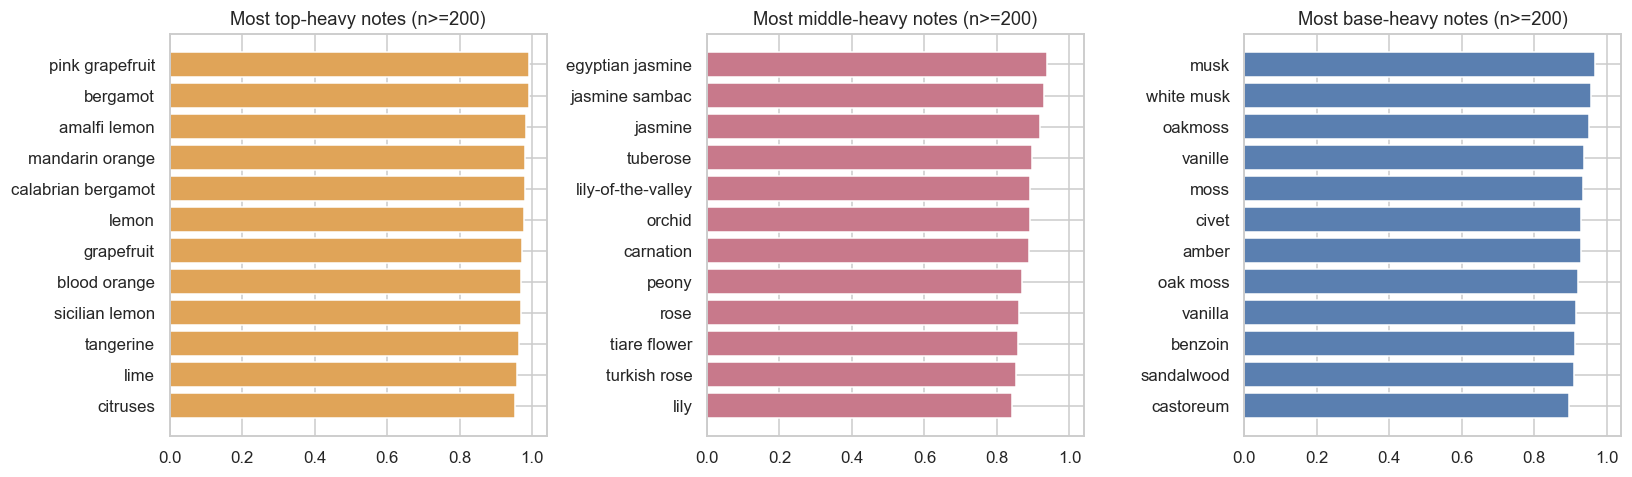

In [7]:
pos = collections.defaultdict(lambda: [0, 0, 0])
for t, m, b in zip(df["Top_list"], df["Middle_list"], df["Base_list"]):
    for k, lst in enumerate((t, m, b)):
        for n in set(lst): pos[n][k] += 1
pos = pd.DataFrame(pos, index=["top", "middle", "base"]).T
pos["total"] = pos.sum(axis=1)
pos = pos[pos["total"] >= 200]
for c in ["top", "middle", "base"]: pos[c + "_share"] = pos[c] / pos["total"]

fig, ax = plt.subplots(1, 3, figsize=(15, 4.5), sharex=True)
for a, c, col in zip(ax, ["top", "middle", "base"], ["#e0a458", "#c8798b", "#5a7fb0"]):
    s = pos[c + "_share"].sort_values(ascending=False).head(12)[::-1]
    a.barh(s.index, s.values, color=col); a.set_title(f"Most {c}-heavy notes (n>=200)")
plt.tight_layout(); plt.show()

## Note associations: lift and PMI

Raw co-occurrence counts mostly surface *popular* notes (bergamot + musk appear together because both appear everywhere).
**Lift** compares how often two notes appear together to what we'd expect if they were independent:

$$\text{lift}(a,b)=\frac{P(a,b)}{P(a)P(b)},\qquad \text{PMI}(a,b)=\log_2 \text{lift}(a,b)$$

Lift > 1 means the pair is used together more than chance; lift < 1 means the notes tend to avoid each other.

In [8]:
mlb_n = MultiLabelBinarizer(sparse_output=True)
Xall = mlb_n.fit_transform(df["all_notes"]).tocsc()
note_names = np.array(mlb_n.classes_)
cnt = np.asarray(Xall.sum(axis=0)).ravel()
keep = np.where(cnt >= MIN_NOTE)[0]
Xn, notes_kept, cnt_k = Xall[:, keep], note_names[keep], cnt[keep]
N = Xn.shape[0]
print(f"{len(notes_kept)} notes appear in >= {MIN_NOTE} perfumes (of {len(note_names)} distinct notes)")

co = sparse.triu((Xn.T @ Xn).tocsr(), k=1).tocoo()
pairs = pd.DataFrame({"note_a": notes_kept[co.row], "note_b": notes_kept[co.col], "count": co.data})
pa, pb = cnt_k[co.row] / N, cnt_k[co.col] / N
pairs["lift"] = (pairs["count"] / N) / (pa * pb)
pairs["pmi"] = np.log2(pairs["lift"])
pairs["jaccard"] = pairs["count"] / (cnt_k[co.row] + cnt_k[co.col] - pairs["count"])
MIN_CO = 30
pairs_f = pairs[pairs["count"] >= MIN_CO].copy()
print(f"{len(pairs_f):,} note pairs with >= {MIN_CO} co-occurrences")

print("\nMost over-represented pairs (highest lift):")
display(pairs_f.sort_values("lift", ascending=False).head(20).round(2).reset_index(drop=True))
print("\nMost frequent pairs (raw count) for comparison:")
display(pairs_f.sort_values("count", ascending=False).head(10).round(2).reset_index(drop=True))
print("\nNotes that avoid each other (lowest lift, both common):")
common = pairs[(cnt_k[co.row] >= 300) & (cnt_k[co.col] >= 300)]
display(common.sort_values("lift").head(10).round(3).reset_index(drop=True))

365 notes appear in >= 50 perfumes (of 1671 distinct notes)
6,360 note pairs with >= 30 co-occurrences

Most over-represented pairs (highest lift):


,note_a,note_b,count,lift,pmi,jaccard
0,castoreum,civet,59,24.73,4.63,0.14
1,cypriol oil or nagarmotha,gurjan balsam,30,22.97,4.52,0.07
2,davana,rum,32,15.72,3.97,0.07
3,fig,fig leaf,33,15.19,3.93,0.08
4,calabrian bergamot,sicilian lemon,30,12.37,3.63,0.07
5,amalfi lemon,oak moss,84,11.89,3.57,0.11
6,hiacynth,orris root,35,11.34,3.50,0.05
7,civet,opoponax,31,11.27,3.49,0.06
8,african orange flower,vanille,134,11.26,3.49,0.13
9,vanille,white honey,32,11.05,3.47,0.04



Most frequent pairs (raw count) for comparison:


,note_a,note_b,count,lift,pmi,jaccard
0,bergamot,musk,4455,1.14,0.18,0.29
1,jasmine,musk,4282,1.23,0.29,0.30
2,musk,sandalwood,4229,1.16,0.21,0.29
3,amber,musk,4128,1.18,0.24,0.28
4,musk,rose,3467,1.24,0.31,0.25
5,bergamot,jasmine,3411,1.24,0.31,0.26
6,bergamot,sandalwood,3395,1.18,0.24,0.26
7,jasmine,sandalwood,3287,1.29,0.36,0.27
8,bergamot,patchouli,3197,1.24,0.31,0.25
9,amber,bergamot,3161,1.15,0.20,0.24



Notes that avoid each other (lowest lift, both common):


,note_a,note_b,count,lift,pmi,jaccard
0,vanilla,vanille,3,0.014,-6.159,0.000
1,cedar,virginia cedar,6,0.026,-5.291,0.001
2,african orange flower,cedar,3,0.035,-4.838,0.001
3,peony,tobacco,2,0.043,-4.530,0.001
4,cedar,vanille,8,0.045,-4.488,0.001
5,vanille,woody notes,2,0.048,-4.376,0.001
6,agarwood (oud),red apple,1,0.049,-4.364,0.001
7,musk,white musk,39,0.049,-4.354,0.003
8,frangipani,lavender,2,0.052,-4.260,0.001
9,cypress,jasmine sambac,1,0.056,-4.164,0.001


**Reading the "avoid each other" table:** the lowest-lift pairs are mostly *synonym or near-duplicate labels* (vanilla/vanille, cedar/virginia cedar, musk/white musk). Perfumers rarely list both, so they look like they repel each other. That's a data-quality finding: merging these variants before building the chord diagram would give cleaner pairs.

## Statistical tests and Bayesian-adjusted ratings

18,958 perfumes with >= 50 ratings

Kruskal-Wallis (rating ~ gender): H = 738.8, p = 3.8e-161
{'women': np.float64(3.92), 'men': np.float64(4.05), 'unisex': np.float64(4.0)} (medians)


,pair,p_bonferroni,rank_biserial
0,women vs men,0.0,0.2817
1,women vs unisex,0.0,0.1687
2,men vs unisex,0.0,-0.1164



Kruskal-Wallis (rating ~ lead accord): H = 1061.9, p = 4.16e-214, epsilon^2 = 0.059


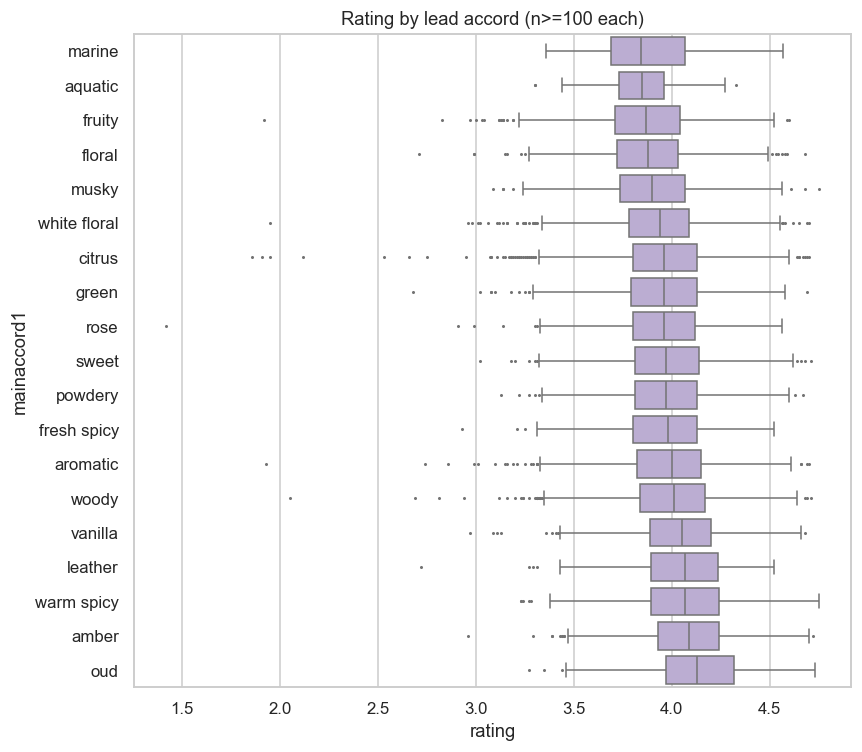

Spearman(rating count, rating) = 0.037 (p = 1.24e-08)


Spearman(rating count, rating) = 0.037 (p = 1.24e-08)


In [9]:
d = df[df["n_ratings"] >= MIN_RATINGS]
print(f"{len(d):,} perfumes with >= {MIN_RATINGS} ratings\n")

# --- Rating by gender label ---
groups = {g: d.loc[d["gender"] == g, "rating"] for g in ["women", "men", "unisex"]}
H, p = stats.kruskal(*groups.values())
print(f"Kruskal-Wallis (rating ~ gender): H = {H:.1f}, p = {p:.3g}")
print({g: round(v.median(), 3) for g, v in groups.items()}, "(medians)")

rows = []
for a, b in itertools.combinations(groups, 2):
    U, pv = stats.mannwhitneyu(groups[a], groups[b], alternative="two-sided")
    rbc = 1 - 2 * U / (len(groups[a]) * len(groups[b]))   # rank-biserial correlation (effect size)
    rows.append({"pair": f"{a} vs {b}", "p_bonferroni": min(pv * 3, 1), "rank_biserial": rbc})
display(pd.DataFrame(rows).round(4))

# --- Rating by lead accord ---
lead = d.groupby("mainaccord1").filter(lambda g: len(g) >= 100)
order = lead.groupby("mainaccord1")["rating"].median().sort_values().index
H2, p2 = stats.kruskal(*[g["rating"].values for _, g in lead.groupby("mainaccord1")])
k, n = lead["mainaccord1"].nunique(), len(lead)
print(f"\nKruskal-Wallis (rating ~ lead accord): H = {H2:.1f}, p = {p2:.3g}, epsilon^2 = {(H2-k+1)/(n-k):.3f}")
plt.figure(figsize=(8, 7))
sns.boxplot(data=lead, y="mainaccord1", x="rating", order=order, color="#b9a7d8", fliersize=1)
plt.title("Rating by lead accord (n>=100 each)"); plt.tight_layout(); plt.show()

# --- Does popularity correlate with rating? ---
rho, pr = stats.spearmanr(df["n_ratings"], df["rating"])
print(f"Spearman(rating count, rating) = {rho:.3f} (p = {pr:.3g})")

Top 12 by RAW rating (dominated by low-count perfumes):


,label,rating,n_ratings,adj_rating
0,Narmar Extrait De Parfum (Nilafar Du Nil),4.93,30,4.212
1,Aoud No 1 (Parfumerie Bruckner),4.86,28,4.186
2,Khaox (Darkbeat Parfums),4.85,26,4.173
3,Cheval D Arabie (Sultan Pasha Attars),4.81,26,4.165
4,Floratta (O Boticario),4.81,31,4.189
5,Art Collection La Nuit De L Homme (Yves Saint ...,4.79,29,4.175
6,Citizen Jack Parfum (Michael Malul London),4.77,30,4.175
7,Xchange Wonderman (Karen Low),4.77,39,4.214
8,Clipping (O Boticario),4.77,26,4.157
9,Dark Door Intense (Maison Alhambra),4.76,37,4.203


Top 12 by ADJUSTED rating:


,label,rating,n_ratings,adj_rating
0,Valentino Uomo Intense 2021 (Valentino),4.68,982,4.617
1,Le Male Le Parfum (Jean Paul Gaultier),4.60,13406,4.596
2,The Most Wanted Parfum (Azzaro),4.59,3842,4.575
3,Emporio Armani Stronger With You Intensely (Gi...,4.57,9587,4.564
4,Dior Homme Original (Dior),4.63,849,4.563
5,The Most Wanted (Azzaro),4.57,4897,4.559
6,Le Male Elixir (Jean Paul Gaultier),4.56,10388,4.555
7,The One Luminous Night (Dolce Gabbana),4.62,841,4.554
8,Le Beau Le Parfum (Jean Paul Gaultier),4.56,7651,4.553
9,Shalimar Parfum (Guerlain),4.63,668,4.548


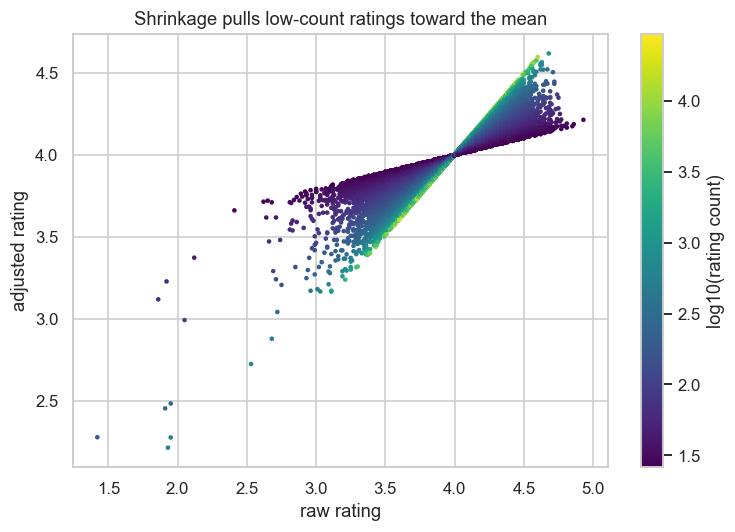

In [10]:
# --- Raw vs Bayesian-adjusted ranking ---
cols = ["label", "rating", "n_ratings", "adj_rating"]
print("Top 12 by RAW rating (dominated by low-count perfumes):")
display(df.sort_values("rating", ascending=False)[cols].head(12).round(3).reset_index(drop=True))
print("Top 12 by ADJUSTED rating:")
display(df.sort_values("adj_rating", ascending=False)[cols].head(12).round(3).reset_index(drop=True))

fig, ax = plt.subplots(figsize=(7, 5))
sc = ax.scatter(df["rating"], df["adj_rating"], c=np.log10(df["n_ratings"]), s=4, cmap="viridis")
plt.colorbar(sc, label="log10(rating count)"); ax.set_xlabel("raw rating"); ax.set_ylabel("adjusted rating")
ax.set_title("Shrinkage pulls low-count ratings toward the mean"); plt.tight_layout(); plt.show()

## Content-based recommender: "find similar perfumes"

Each perfume is a bag of tokens: its notes (weighted by pyramid position: base/middle/top counted separately as well) plus its main accords.
TF-IDF down-weights ubiquitous notes (musk, bergamot) so rarer, more distinctive notes drive similarity. Cosine similarity ranks neighbours.

In [11]:
def tokens(r):
    t = [f"n:{n}" for n in r["all_notes"]]
    t += [f"acc:{a}" for a in r["accords"]]
    t += [f"acc:{a}" for a in r["accords"][:2]]             # lead accords count extra
    t += [f"top:{n}" for n in r["Top_list"]] + [f"mid:{n}" for n in r["Middle_list"]] + [f"base:{n}" for n in r["Base_list"]]
    return t

docs = df.apply(tokens, axis=1)
tfidf = TfidfVectorizer(analyzer=lambda x: x, min_df=5, sublinear_tf=True)
T = tfidf.fit_transform(docs)             # sparse, L2-normalised rows
print("TF-IDF matrix:", T.shape)

def find(query, brand=None):
    m = df["perfume"].str.contains(query.lower().replace(" ", "-"), regex=False)
    if brand: m &= df["brand"].str.contains(brand.lower().replace(" ", "-"), regex=False)
    return df[m].sort_values("n_ratings", ascending=False)

def recommend(query, brand=None, n=10, same_gender=False, min_ratings=MIN_RATINGS):
    hit = find(query, brand)
    if hit.empty: raise ValueError(f"No perfume matching '{query}'")
    i = hit.index[0]
    sims = (T @ T[i].T).toarray().ravel()
    out = df.assign(similarity=sims).drop(index=i)
    out = out[out["n_ratings"] >= min_ratings]
    if same_gender: out = out[out["gender"] == df.loc[i, "gender"]]
    print(f"Because you liked: {df.loc[i, 'label']}  | accords: {', '.join(df.loc[i, 'accords'])}")
    return out.sort_values("similarity", ascending=False)[["label", "gender", "accords", "similarity", "adj_rating"]].head(n).round(3)

recommend("sauvage", brand="dior")

TF-IDF matrix: (24063, 2677)
Because you liked: Sauvage (Dior)  | accords: fresh spicy, amber, citrus, aromatic, musky


,label,gender,accords,similarity,adj_rating
19952,Sauvage Very Cool Spray (Dior),men,"[fresh spicy, citrus, aromatic, amber, woody]",0.864,4.195
22898,I Am The King (Ard Al Zaafaran),men,"[fresh spicy, aromatic, citrus, amber, woody]",0.842,4.225
19362,Vodka Wild (Paris Elysees),men,"[fresh spicy, citrus, aromatic, lavender, woody]",0.630,4.115
22934,Club De Nuit Urban Elixir (Armaf),men,"[amber, aromatic, citrus, fresh spicy, musky]",0.568,4.375
20367,Odyssey Tyrant Special Edition (Armaf),men,"[citrus, fresh spicy, aromatic, amber, woody]",0.543,4.095
22964,Salvo (Maison Alhambra),men,"[fresh spicy, citrus, amber, lavender, musky]",0.468,4.164
19183,Sauvage Eau De Parfum (Dior),men,"[fresh spicy, citrus, amber, lavender, musky]",0.468,4.188
13352,Honour Man (Amouage),men,"[fresh spicy, aromatic, woody, warm spicy, amber]",0.440,4.009
8869,Capsule Collection This Is Him Edition 2019 (Z...,men,"[amber, aromatic, citrus, woody, fresh spicy]",0.419,3.950
1860,Guess Night (Guess),men,"[fresh spicy, aromatic, woody, vanilla, warm s...",0.414,3.701


In [12]:
recommend("aventus", n=8)

Because you liked: Aventus (Creed)  | accords: fruity, sweet, leather, woody, smoky


,label,gender,accords,similarity,adj_rating
22330,Alexa By Projekt Alternative (Perfumologist),unisex,"[fruity, citrus, sweet, tropical, woody]",0.640,4.116
16424,Supremacy Silver (Afnan),men,"[fruity, leather, woody, sweet, smoky]",0.604,4.084
10716,Invincibile (Tonino Lamborghini),men,"[fruity, woody, leather, smoky, citrus]",0.590,3.973
20559,Matar (Spirit Of Kings),unisex,"[fruity, woody, sweet, mossy, leather]",0.560,4.129
7956,New Aventhis (In The Box),men,"[fruity, woody, mossy, leather, earthy]",0.539,3.946
20173,Oud Mood Silver (Lattafa Perfumes),men,"[rose, woody, earthy, vanilla, amber]",0.456,4.106
18355,Club De Nuit Intense Man (Armaf),men,"[citrus, fruity, leather, smoky, woody]",0.434,4.159
22526,Club De Nuit Intense Man Parfum (Armaf),men,"[citrus, fruity, leather, smoky, woody]",0.434,4.352


In [13]:
rng = np.random.default_rng(SEED)
sample = rng.choice(len(df), 500, replace=False)
hits, base = [], (df["mainaccord1"].value_counts(normalize=True) ** 2).sum()
for i in sample:
    s = (T @ T[i].T).toarray().ravel(); s[i] = -1
    nn = np.argsort(-s)[:10]
    hits.append((df["mainaccord1"].values[nn] == df["mainaccord1"].values[i]).mean())
print(f"Top-10 neighbours share the query's lead accord {np.mean(hits):.1%} of the time (random baseline ~ {base:.1%})")

Top-10 neighbours share the query's lead accord 34.8% of the time (random baseline ~ 7.5%)


## Predictive models

### What predicts a perfume's rating?
Features: note presence (multi-hot), accords, gender label, release decade, country. Target: rating, restricted to perfumes with enough votes.
Expect modest R² — taste is subjective — so the interesting output is *which* notes carry signal.

In [14]:
note_vocab_min = 100
mlb_a = MultiLabelBinarizer()
Xa = pd.DataFrame(mlb_a.fit_transform(df["accords"]), index=df.index, columns=[f"acc:{c}" for c in mlb_a.classes_])
nc = np.asarray(Xall.sum(axis=0)).ravel()
keep100 = np.where(nc >= note_vocab_min)[0]
Xnote = pd.DataFrame(Xall[:, keep100].toarray(), index=df.index, columns=[f"n:{c}" for c in note_names[keep100]])

meta = pd.DataFrame(index=df.index)
meta["year"] = df["year"].fillna(df["year"].median())
meta["year_missing"] = df["year"].isna().astype(int)
for g in ["men", "unisex"]: meta[f"g:{g}"] = (df["gender"] == g).astype(int)
for c in df["country"].value_counts().head(8).index: meta[f"c:{c}"] = (df["country"] == c).astype(int)

X_all = pd.concat([Xnote, Xa, meta], axis=1)
print("feature matrix:", X_all.shape)

mask = (df["n_ratings"] >= MIN_RATINGS).values
X, y = X_all[mask], df.loc[mask, "rating"]
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.2, random_state=SEED)

baseline = np.sqrt(mean_squared_error(yte, np.full(len(yte), ytr.mean())))
ridge = RidgeCV(alphas=np.logspace(-1, 3, 20)).fit(Xtr, ytr)
hgb = HistGradientBoostingRegressor(max_iter=300, learning_rate=0.05, max_depth=6, random_state=SEED).fit(Xtr, ytr)

res = pd.DataFrame({
    "model": ["mean baseline", "Ridge", "HistGradientBoosting"],
    "R2": [0.0, r2_score(yte, ridge.predict(Xte)), r2_score(yte, hgb.predict(Xte))],
    "RMSE": [baseline, np.sqrt(mean_squared_error(yte, ridge.predict(Xte))), np.sqrt(mean_squared_error(yte, hgb.predict(Xte)))],
}).round(3)
display(res)
print("Ridge alpha:", round(ridge.alpha_, 2))

feature matrix: (24063, 367)


,model,R2,RMSE
0,mean baseline,0.000,0.259
1,Ridge,0.135,0.241
2,HistGradientBoosting,0.161,0.237


Ridge alpha: 88.59


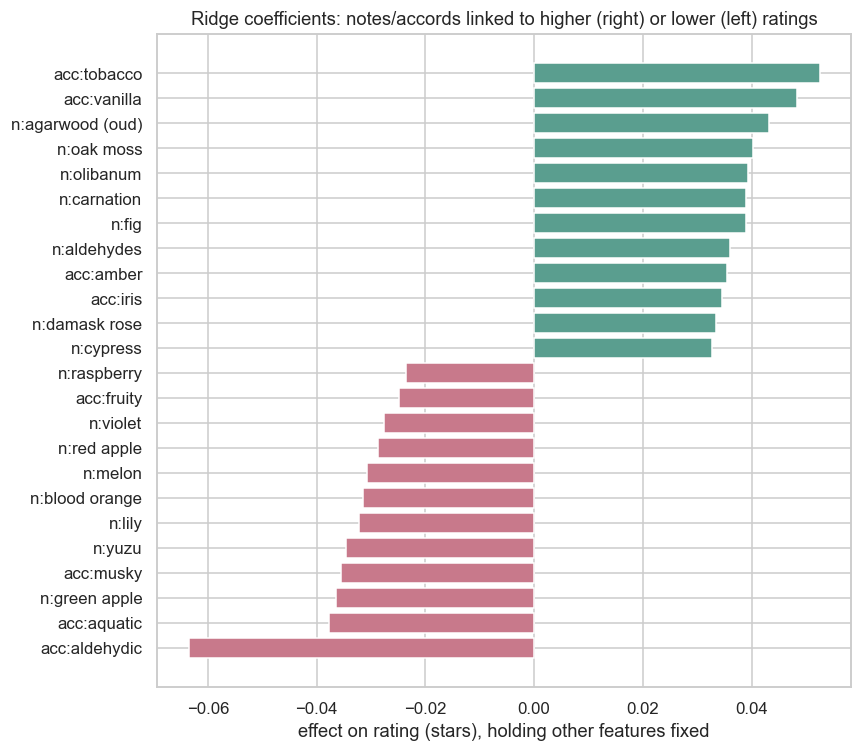

Year / gender / country coefficients:


,year,year_missing,g:men,g:unisex,c:France,c:USA,c:Italy,c:UK,c:Brazil,c:Spain,c:UAE,c:Germany
coef,-0.002,-0.012,0.09,0.028,0.033,-0.016,0.013,0.055,0.123,0.021,0.095,-0.019


In [15]:
coef = pd.Series(ridge.coef_, index=X.columns)
coef_notes = coef[coef.index.str.startswith(("n:", "acc:"))]
cnt_feat = X.sum()
coef_notes = coef_notes[cnt_feat[coef_notes.index] >= 200]       # only reasonably common features
sel = pd.concat([coef_notes.sort_values().head(12), coef_notes.sort_values().tail(12)])

plt.figure(figsize=(8, 7))
plt.barh(sel.index, sel.values, color=np.where(sel.values > 0, "#5a9e8f", "#c8798b"))
plt.title("Ridge coefficients: notes/accords linked to higher (right) or lower (left) ratings")
plt.xlabel("effect on rating (stars), holding other features fixed"); plt.tight_layout(); plt.show()
print("Year / gender / country coefficients:")
display(coef[~coef.index.str.startswith(("n:", "acc:"))].round(3).to_frame("coef").T)

### Can we predict the gender label from the scent profile?
Uses notes + accords only. The 'unisex' class is expected to be the hardest, since it overlaps both others.

              precision    recall  f1-score   support

         men      0.636     0.784     0.702       998
      unisex      0.619     0.539     0.576      1540
       women      0.824     0.812     0.818      2275

    accuracy                          0.719      4813
   macro avg      0.693     0.712     0.699      4813
weighted avg      0.719     0.719     0.717      4813



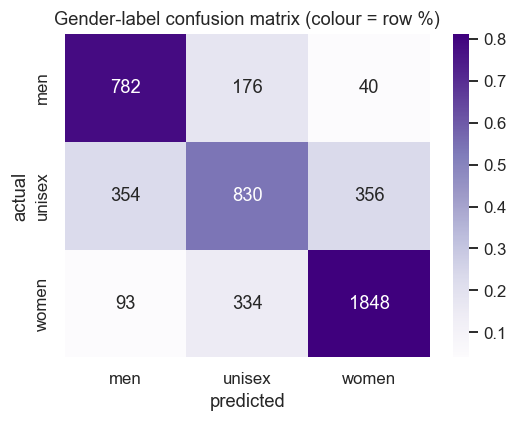


Most 'men'-indicative features: n:lavender, n:water notes, n:sage, acc:whiskey, n:watery notes, n:red apple, n:pineapple, acc:wine, n:leather, n:green apple

Most 'unisex'-indicative features: n:sweet orange, n:turkish rose, n:haitian vetiver, n:beeswax, n:madagascar vanilla, n:egyptian jasmine, n:agarwood (oud), n:oak, n:damask rose, n:carrot seeds

Most 'women'-indicative features: n:narcissus, n:hiacynth, n:peony, n:orchid, n:red currant, n:vanilla orchid, n:vanila, n:vanille, n:jasmine sambac, n:white rose


In [16]:
Xg = pd.concat([Xnote, Xa], axis=1)
yg = df["gender"]
Xtr, Xte, ytr, yte = train_test_split(Xg, yg, test_size=0.2, random_state=SEED, stratify=yg)

clf = LogisticRegression(max_iter=3000, C=0.5, class_weight="balanced").fit(Xtr, ytr)
pred = clf.predict(Xte)
print(classification_report(yte, pred, digits=3))

cm = pd.DataFrame(confusion_matrix(yte, pred, labels=clf.classes_), index=clf.classes_, columns=clf.classes_)
plt.figure(figsize=(5, 4)); sns.heatmap(cm.div(cm.sum(axis=1), axis=0), annot=cm, fmt="d", cmap="Purples")
plt.xlabel("predicted"); plt.ylabel("actual"); plt.title("Gender-label confusion matrix (colour = row %)"); plt.tight_layout(); plt.show()

W = pd.DataFrame(clf.coef_.T, index=Xg.columns, columns=clf.classes_)
for g in clf.classes_:
    print(f"\nMost '{g}'-indicative features:", ", ".join(W[g].sort_values(ascending=False).head(10).index))

## Clustering: data-driven scent families

The chord-diagram notebook assigns notes to families with hand-written keyword rules. Here the data decides: reduce the TF-IDF matrix with SVD,
then cluster perfumes with k-means and ask how closely the clusters line up with the lead accord.

variance explained by 40 components: 27.1%


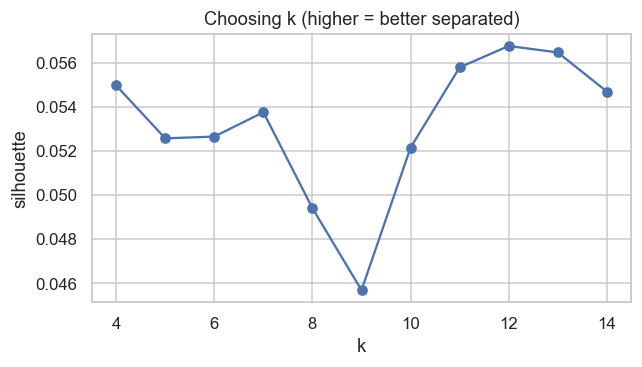

In [17]:
svd = TruncatedSVD(n_components=40, random_state=SEED)
Z = svd.fit_transform(T)
print("variance explained by 40 components: %.1f%%" % (svd.explained_variance_ratio_.sum() * 100))

idx = np.random.default_rng(SEED).choice(len(Z), 6000, replace=False)
ks = range(4, 15)
sil = []
for k in ks:
    km = KMeans(k, n_init=5, random_state=SEED).fit(Z[idx])
    sil.append(silhouette_score(Z[idx], km.labels_))
plt.figure(figsize=(6, 3.5)); plt.plot(list(ks), sil, marker="o"); plt.xlabel("k"); plt.ylabel("silhouette")
plt.title("Choosing k (higher = better separated)"); plt.tight_layout(); plt.show()

In [18]:
K = 10   # adjust after looking at the silhouette curve
km = KMeans(K, n_init=10, random_state=SEED).fit(Z)
df["cluster"] = km.labels_
print("cluster sizes:", df["cluster"].value_counts().sort_index().to_dict())
print("Adjusted Rand Index vs lead accord: %.3f  (0 = unrelated, 1 = identical)" % adjusted_rand_score(df["mainaccord1"], df["cluster"]))

# describe each cluster by its most over-represented accords and notes
note_df = pd.DataFrame(Xall[:, keep].toarray(), columns=notes_kept)
prof = []
for c in range(K):
    m = (df["cluster"] == c).values
    a_lift = (A[m].mean() / A.mean()).where(A[m].sum() >= 20).dropna().sort_values(ascending=False).head(4)
    n_lift = (note_df[m].mean() / note_df.mean()).where(note_df[m].sum() >= 20).dropna().sort_values(ascending=False).head(6)
    prof.append({"cluster": c, "size": int(m.sum()), "accords": ", ".join(a_lift.index),
                 "signature notes": ", ".join(n_lift.index),
                 "women %": round((df.loc[m, "gender"] == "women").mean() * 100), "median adj rating": round(df.loc[m, "adj_rating"].median(), 2)})
display(pd.DataFrame(prof).set_index("cluster"))

cluster sizes: {0: 1483, 1: 1794, 2: 2391, 3: 3668, 4: 2731, 5: 1578, 6: 3100, 7: 3861, 8: 2532, 9: 925}
Adjusted Rand Index vs lead accord: 0.195  (0 = unrelated, 1 = identical)


,size,accords,signature notes,women %,median adj rating
cluster,,,,,
0,1483,"iris, violet, powdery, aldehydic","iris, violet, carrot seeds, powdery notes, orr...",60,4.00
1,1794,"lavender, herbal, fresh spicy, aromatic","lavender, rosemary, tarragon, caraway, geraniu...",8,4.00
2,2391,"almond, vanilla, coconut, nutty","whipped cream, bitter almond, almond, coconut ...",58,4.01
3,3668,"smoky, balsamic, cinnamon, whiskey","smoke, castoreum, opoponax, myrrh, whiskey, to...",20,4.03
4,2731,"tuberose, white floral, yellow floral, animalic","tuberose, orange blossom, gardenia, hiacynth, ...",74,3.97
5,1578,"rose, floral, patchouli, musky","grasse rose, rose water, may rose, damask rose...",75,3.96
6,3100,"tropical, fruity, cherry, caramel","wild strawberry, big strawberry, strawberry, m...",73,3.95
7,3861,"conifer, marine, cannabis, salty","seaweed, gin, verbena, sea notes, mint, sea water",16,3.99
8,2532,"aquatic, fresh, floral, ozonic","water lily, peony, cucumber, pink peony, lotus...",81,3.93


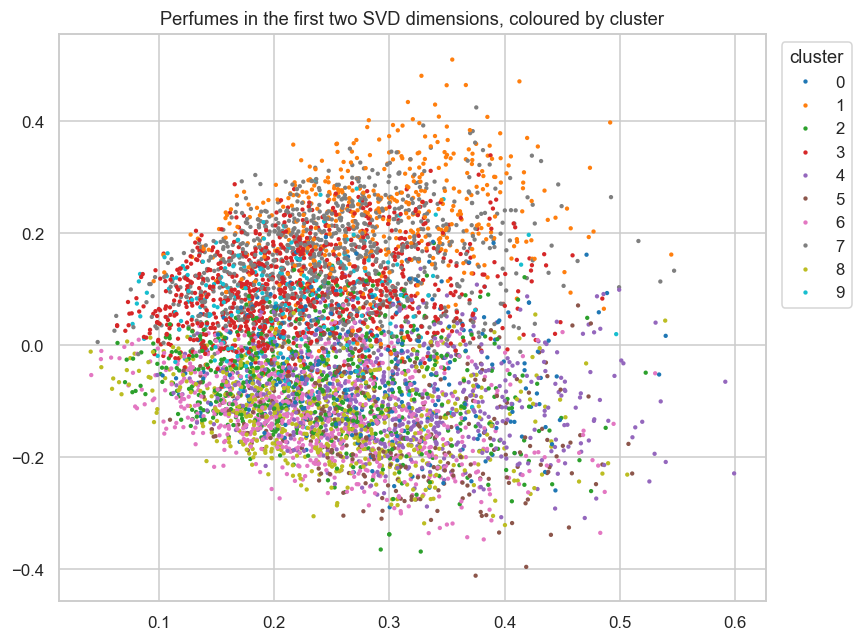

In [19]:
sub = np.random.default_rng(1).choice(len(Z), 6000, replace=False)
plt.figure(figsize=(8, 6))
sns.scatterplot(x=Z[sub, 0], y=Z[sub, 1], hue=df["cluster"].values[sub], palette="tab10", s=8, linewidth=0)
plt.title("Perfumes in the first two SVD dimensions, coloured by cluster")
plt.legend(title="cluster", bbox_to_anchor=(1.01, 1), loc="upper left"); plt.tight_layout(); plt.show()

## Note network and communities

Build a graph whose nodes are notes and whose edges connect pairs with high lift (and enough support).
Louvain community detection finds groups of notes that cluster together; betweenness centrality highlights "bridge" notes that connect otherwise separate groups.

In [20]:
import networkx as nx
TOP_NODES, LIFT_MIN, CO_MIN = 150, 1.5, 40
top_notes = set(pd.Series(cnt_k, index=notes_kept).sort_values(ascending=False).head(TOP_NODES).index)
E = pairs[(pairs["count"] >= CO_MIN) & (pairs["lift"] >= LIFT_MIN) &
          pairs["note_a"].isin(top_notes) & pairs["note_b"].isin(top_notes)]
G = nx.Graph()
G.add_nodes_from(top_notes)
for r in E.itertuples(): G.add_edge(r.note_a, r.note_b, weight=r.pmi)
G.remove_nodes_from([n for n in list(G) if G.degree(n) == 0])
print(f"graph: {G.number_of_nodes()} nodes, {G.number_of_edges()} edges")

comms = nx.community.louvain_communities(G, weight="weight", seed=SEED)
comms = sorted(comms, key=len, reverse=True)
freq = pd.Series(cnt_k, index=notes_kept)
for i, c in enumerate(comms):
    print(f"Community {i} ({len(c)} notes): " + ", ".join(sorted(c, key=lambda n: -freq[n])[:12]))

btw = pd.Series(nx.betweenness_centrality(G)).sort_values(ascending=False)
print("\nTop 'bridge' notes (betweenness):", ", ".join(btw.head(10).index))

graph: 147 nodes, 1181 edges
Community 0 (38 notes): mandarin orange, lily-of-the-valley, violet, peach, freesia, white musk, black currant, peony, pear, raspberry, magnolia, apple
Community 1 (34 notes): musk, bergamot, sandalwood, amber, jasmine, vanilla, rose, tonka bean, orange blossom, iris, ylang-ylang, neroli
Community 2 (33 notes): cedar, vetiver, lemon, lavender, cardamom, grapefruit, geranium, oakmoss, nutmeg, ginger, pepper, mint
Community 3 (30 notes): patchouli, pink pepper, leather, benzoin, cinnamon, agarwood (oud), incense, saffron, labdanum, ambergris, black pepper, guaiac wood
Community 4 (12 notes): orange, woody notes, virginia cedar, citruses, woodsy notes, vanille, amalfi lemon, spices, floral notes, african orange flower, clove, oak moss

Top 'bridge' notes (betweenness): carnation, peach, green notes, oakmoss, ylang-ylang, lavender, lily-of-the-valley, cardamom, cinnamon, white musk


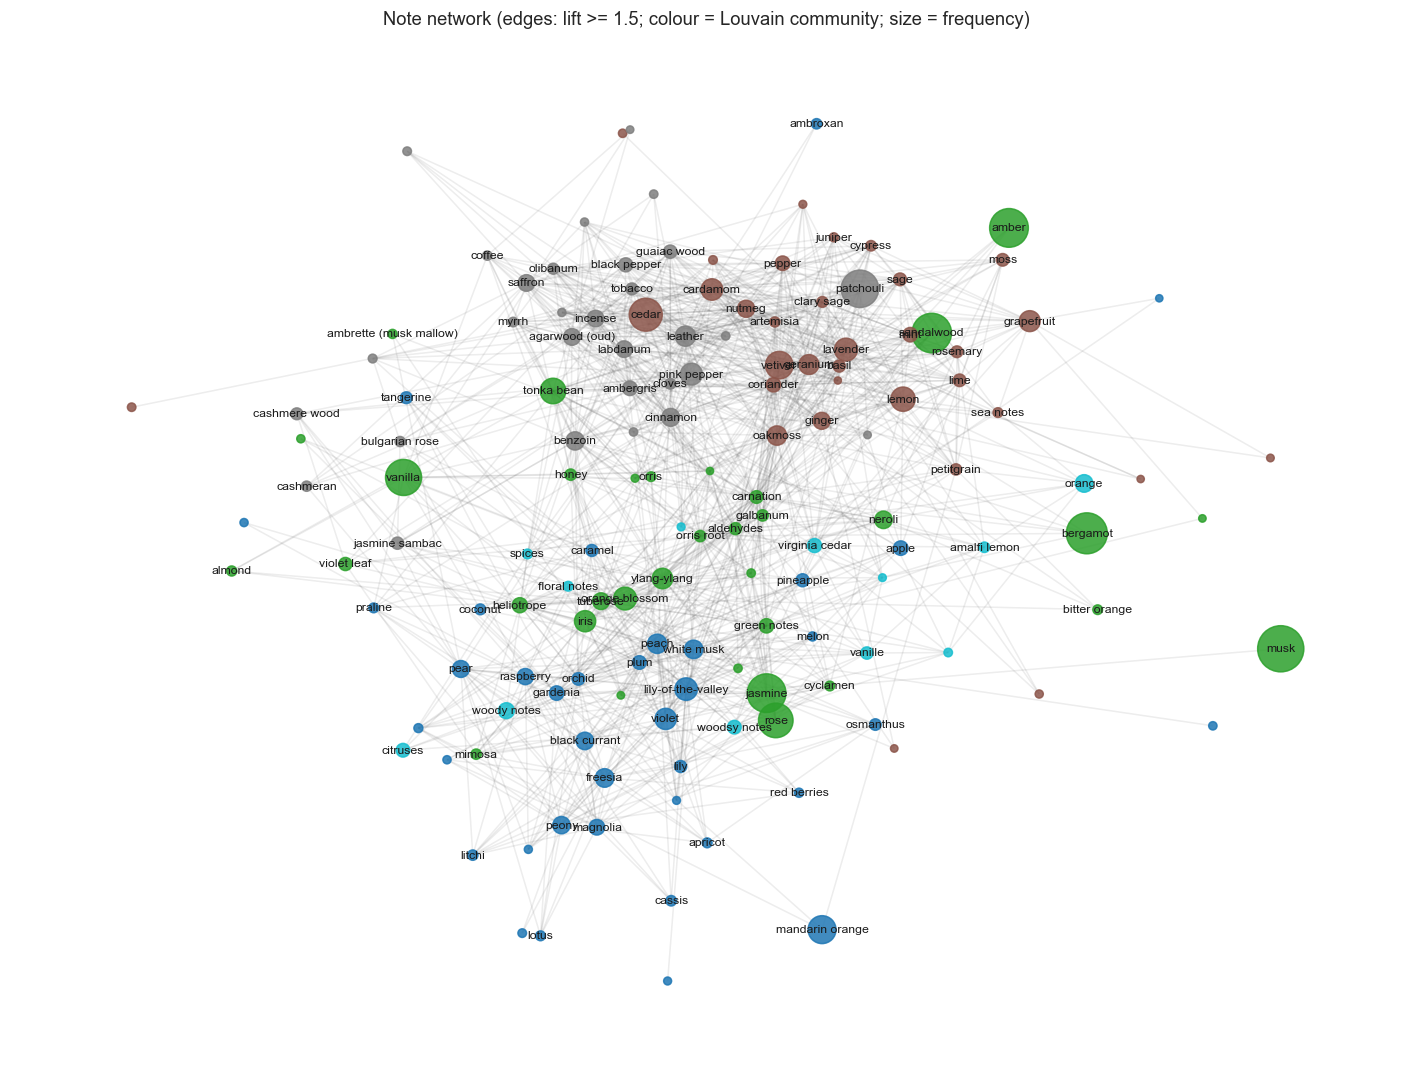

In [21]:
member = {n: i for i, c in enumerate(comms) for n in c}
pos_xy = nx.spring_layout(G, weight="weight", seed=SEED, k=0.6)
fig, ax = plt.subplots(figsize=(13, 10))
nx.draw_networkx_edges(G, pos_xy, alpha=0.08, ax=ax)
nx.draw_networkx_nodes(G, pos_xy, node_size=[freq[n] / 12 for n in G], node_color=[member[n] for n in G], cmap="tab10", alpha=0.85, ax=ax)
nx.draw_networkx_labels(G, pos_xy, labels={n: n for n in G if freq[n] >= freq.quantile(0.7)}, font_size=8, ax=ax)
ax.set_title("Note network (edges: lift >= %.1f; colour = Louvain community; size = frequency)" % LIFT_MIN); ax.axis("off")
plt.tight_layout(); plt.show()

## Export results
Saves lift-based pairs (a better edge list for the chord diagram) and per-perfume cluster / adjusted-rating assignments.

In [22]:
pairs_f.sort_values("lift", ascending=False).round(4).to_csv("note_pairs_lift.csv", index=False)
df[["url", "label", "cluster", "rating", "n_ratings", "adj_rating"]].to_csv("perfume_clusters.csv", index=False)
print("wrote note_pairs_lift.csv and perfume_clusters.csv")

wrote note_pairs_lift.csv and perfume_clusters.csv
